<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/05_hydrometeor_classification_fuzzy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 5: จำแนกชนิดหยาดน้ำฟ้าแบบ fuzzy (Hydrometeor Identification, HID)
### Fuzzy-logic and semi-supervised hydrometeor classification, class evolution and vertical structure

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 1 และ 4

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **อธิบายหลักการ fuzzy logic** (membership → aggregation → decision) และวิธี semi-supervised ของ Besic et al. (2016) ใน Py-ART
2. **จำแนกชนิดหยาดน้ำฟ้า 9 คลาส** จากข้อมูล KKN และทำแผนที่/ภาคตัดขวางคุณภาพตีพิมพ์
3. **วิเคราะห์สัดส่วนและพัฒนาการของคลาส** ตามเวลา และแยกส่วนที่อยู่ใต้–เหนือระดับ 0 °C
4. **เชื่อมผล HID กับรายงานลูกเห็บ** ที่นากลางและภูกระดึง
5. **ประเมินความไวของผล** ต่อ ZDR bias และระดับเยือกแข็ง และอธิบายความไม่แน่นอน (entropy)

## 📖 1. แนวคิดและสมการ

### 1.1 Fuzzy logic แบบดั้งเดิม (Straka et al., 2000; Liu & Chandrasekar, 2000)
1. **Fuzzification:** แต่ละตัวแปร $x_j$ (Z, ZDR, KDP, ρHV, T) แปลงเป็นค่า **membership** $\mu_{c,j}(x_j) \in [0, 1]$ ของแต่ละคลาส $c$ (มักเป็นรูปสี่เหลี่ยมคางหมู)
2. **Aggregation:** รวมแบบถ่วงน้ำหนัก
$$ S_c = \frac{\sum_j w_j\,\mu_{c,j}(x_j)}{\sum_j w_j} $$
3. **Decision:** เลือกคลาสที่ $S_c$ สูงสุด $\;\hat{c} = \arg\max_c S_c$

### 1.2 Semi-supervised (Besic et al., 2016) — วิธีที่ Py-ART ใช้
- ใช้ข้อมูลเรดาร์จริงจำนวนมาก + ความรู้ทางฟิสิกส์ หา **จุดศูนย์กลาง (centroid)** ของแต่ละคลาสในปริภูมิ 5 มิติ $(Z_H, Z_{DR}, K_{DP}, \rho_{HV}, \Delta h)$
  โดย $\Delta h$ = ความสูงเทียบกับระดับ 0 °C (คำนวณจากอุณหภูมิ: $\Delta h = T \times 1000/\Gamma$, $\Gamma = -6.5$ °C/km)
- แต่ละ gate ถูกจัดเข้าคลาสที่ **ระยะทางถ่วงน้ำหนัก** (หลังทำ standardization) ไปยัง centroid **สั้นที่สุด**
$$ d_c = \sqrt{\sum_j w_j\,(\tilde{x}_j - \tilde{m}_{c,j})^2},\qquad \hat{c} = \arg\min_c d_c,\qquad w = (1, 1, 1, 0.75, 0.5) $$
- **Entropy** บอกความไม่แน่นอน: ถ้าระยะถึงหลายคลาสใกล้กัน → entropy สูง (จำแนกไม่ชัด)

### 1.3 คลาสทั้ง 9 (+NC)
| รหัส | คลาส | ลักษณะเด่นของเรดาร์ |
|---|---|---|
| AG | Aggregates (เกล็ดหิมะรวมตัว) | Z ต่ำ–กลาง, ZDR ~0.2–0.5, เหนือ 0 °C |
| CR | Ice crystals | Z ต่ำมาก, ZDR บวก, สูงมาก |
| LR | Light rain | Z < 30, ZDR ต่ำ, ใต้ 0 °C |
| RP | Rimed particles (graupel) | Z 25–40, ZDR ~0, ρHV สูง, เหนือ 0 °C |
| RN | Rain | Z 30–50, ZDR 1–3, KDP บวก |
| VI | Vertically aligned ice | ZDR **ติดลบ** (ผลึกเรียงตัวในสนามไฟฟ้า) |
| WS | Wet snow (ชั้นละลาย) | ρHV ต่ำ, ZDR สูง, ใกล้ 0 °C |
| MH | Melting hail | Z > 50, ZDR สูง, KDP สูง, ใต้ 0 °C |
| IH/HDG | Ice hail / high-density graupel | Z > 45, ZDR ~0, KDP ~0, เหนือ 0 °C |

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_HID_Doppler_KKN_summerStorm/data


In [2]:
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
peak = pt.polar_files(DATA, "09:00", "10:45")
radar = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar)
reports = kt.load_reports(DATA, meta)
NK, PK = kt.site(reports, "Na Klang"), kt.site(reports, "Phu Kradueng")
NW = kt.box_around(meta, 102.3, 17.3, 90)
ISO = {"0 °C": pt.isotherm_height(snd, 0), "−20 °C": pt.isotherm_height(snd, -20)}


def prepare(r):
    """ขั้นตอนจาก NB4: อุณหภูมิ → ΦDP/KDP → ZDR bias → Z-PHI"""
    pt.add_temperature(r, snd); pt.process_phidp(r); pt.add_kdp(r)
    pt.correct_zdr_bias(r); pt.correct_attenuation(r)
    return r


import pyart.retrieve.echo_class as _ec
centroids = pd.DataFrame(_ec._get_mass_centers(pt.RADAR_FREQ_HZ), index=pt.HID_NAMES[1:],
                         columns=["Zh (dBZ)", "ZDR (dB)", "KDP (°/km)", "RhoHV", "Δh (m)"])
print("centroid ของแต่ละคลาสที่ C-band (Py-ART / Besic et al. 2016)")
centroids.round(2)

centroid ของแต่ละคลาสที่ C-band (Py-ART / Besic et al. 2016)


,Zh (dBZ),ZDR (dB),KDP (°/km),RhoHV,Δh (m)
AG,13.58,0.41,0.05,0.99,1330.3
CR,2.85,0.25,0.00,0.98,653.8
LR,7.66,0.22,0.00,0.98,-1426.5
RP,31.68,0.39,0.08,1.00,535.3
RN,39.47,1.07,0.49,0.99,-1036.3
VI,4.83,-0.57,0.00,0.97,869.8
WS,30.86,0.98,0.20,0.98,-66.1
MH,52.40,2.11,2.47,0.97,-1550.2
IH/HDG,50.62,-0.06,0.09,0.99,1179.9


สังเกตว่า centroid ของ $\rho_{HV}$ อยู่ที่ 0.97–1.00 แต่ใน NB1 พบว่า ρHV ในฝนของ KKN ~0.95 → อาจทำให้บาง gate ถูกดึงไปคลาสที่ ρHV ต่ำ (WS/MH) — เป็นเหตุผลที่ Py-ART ให้น้ำหนัก ρHV น้อยกว่า (0.75)

## 🧊 3. HID ที่ 09:30 UTC (16:30 น.)

In [3]:
prepare(radar)
pt.classify_hid(radar, entropy=True)
cnt = pd.Series(pt.hid_counts(radar))
print("จำนวน gate ต่อคลาส (ทุกมุมยก):"); print((cnt / cnt.sum() * 100).round(1).astype(str) + " %")

จำนวน gate ต่อคลาส (ทุกมุมยก):
AG        14.2 %
CR         0.6 %
LR        38.2 %
RP         4.3 %
RN        15.5 %
VI        15.4 %
WS         5.2 %
MH         3.6 %
IH/HDG     3.0 %
dtype: str


บันทึกรูปแล้ว: figures/nb5_hid_0930.png, figures/nb5_hid_0930.pdf


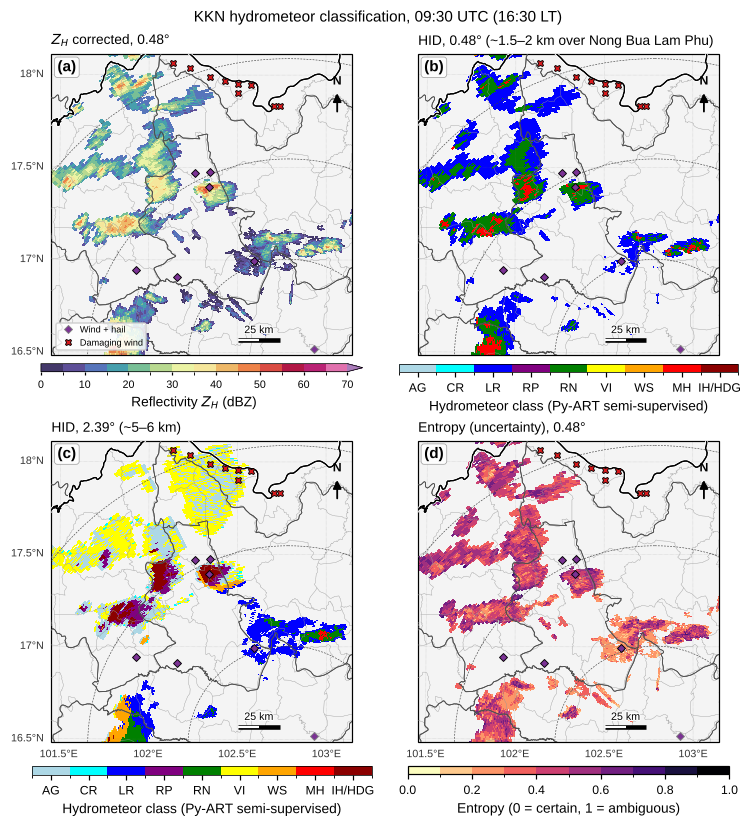

In [4]:
fig, axs = mp.map_panels(2, 2, meta, panel_width=3.4, zoom=NW)
im0 = pt.ppi_map(axs[0], radar, "DBZ_C", 0, meta, kind="Z", zoom=NW, title="$Z_H$ corrected, 0.48°",
                 gridline_labels=("left",))
im1 = pt.ppi_map(axs[1], radar, "HID", 0, meta, kind="HID", zoom=NW, title="HID, 0.48° (~1.5–2 km over Nong Bua Lam Phu)",
                 gridline_labels=(), north=True)
im2 = pt.ppi_map(axs[2], radar, "HID", 2, meta, kind="HID", zoom=NW, title="HID, 2.39° (~5–6 km)",
                 gridline_labels=("left", "bottom"))
im3 = pt.ppi_map(axs[3], radar, "HID_ENTROPY", 0, meta, zoom=NW, cmap="magma_r",
                 norm=plt.matplotlib.colors.BoundaryNorm(np.arange(0, 1.01, 0.1), 256), title="Entropy (uncertainty), 0.48°",
                 gridline_labels=("bottom",))
for ax in axs:
    mp.add_reports(ax, reports, legend=(ax is axs[0]), ms=4)
mp.add_colorbar(fig, im0, axs[0], shrink=0.9)
pt.hid_colorbar(fig, im1, axs[1], shrink=0.95)
pt.hid_colorbar(fig, im2, axs[2], shrink=0.95)
cb = fig.colorbar(im3, ax=axs[3], orientation="horizontal", shrink=0.9, pad=0.02, aspect=40)
cb.set_label("Entropy (0 = certain, 1 = ambiguous)")
mp.panel_labels(axs)
fig.suptitle(f"KKN hydrometeor classification, {mp.tlabel(pt.volume_time(radar))}", fontsize=10)
mp.save_figure(fig, "nb5_hid_0930")
plt.show()

- (b) มุมต่ำ: ส่วนใหญ่เป็น **ฝน (LR/RN)** และมี **MH (แดง) กลางแกนพายุ** ใกล้นากลาง/สุวรรณคูหา
- (c) มุม 2.39° ลำคลื่นอยู่เหนือระดับ 0 °C ที่ระยะ > ~110 km → เปลี่ยนเป็นคลาส **น้ำแข็ง (AG, VI, RP, IH/HDG)**
- (d) **entropy สูง** ที่ขอบพายุและบริเวณใกล้ระดับละลาย = ผลจำแนกไม่แน่นอน ควรระวังเมื่อแปลผล

## ⏱️ 4. พัฒนาการของ HID ทุก 15 นาที รอบนากลาง (มุมยก 1.48°)

บันทึกรูปแล้ว: figures/nb5_hid_evolution_maps.png, figures/nb5_hid_evolution_maps.pdf


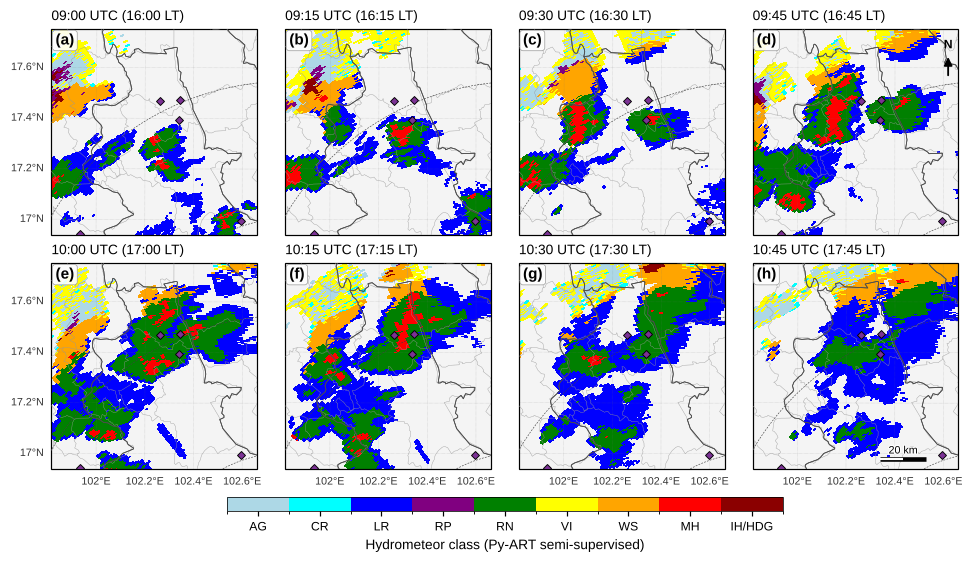

In [5]:
ZNK = kt.box_around(meta, NK["lon"] - 0.1, NK["lat"] - 0.05, 45)
vols, rows = {}, []
for f in peak:
    r = prepare(pt.read_volume(f))
    pt.classify_hid(r)
    pt.keep_fields(r, ["HID", "DBZ_C", "ZDR_C", "KDP", "temperature", "cross_correlation_ratio_qc"])   # ประหยัดหน่วยความจำ
    vols[pt.volume_time(r)] = r
    h = np.ma.filled(r.fields["HID"]["data"], 0)
    T = pt.field_data(r, "temperature")
    c = pt.hid_counts(r)
    row = {"time": pt.volume_time(r), **c}
    for grp, ids in pt.HID_GROUPS.items():
        row[f"n_{grp}"] = int(np.isin(h, ids).sum())
    row["n_warm"] = int(((h > 0) & (T > 0)).sum()); row["n_cold"] = int(((h > 0) & (T <= 0)).sum())
    rows.append(row)
hid_ts = pd.DataFrame(rows).set_index("time")

fig, axs = mp.map_panels(2, 4, meta, panel_width=2.2, zoom=ZNK)
for k, (t, r) in enumerate(vols.items()):
    im = pt.ppi_map(axs[k], r, "HID", 1, meta, kind="HID", zoom=ZNK, title=mp.tlabel(t), scalebar=(k == 7),
                    north=(k == 3), gridline_labels=(("left",) if k % 4 == 0 else ()) + (("bottom",) if k >= 4 else ()))
    mp.add_reports(axs[k], reports, legend=False, ms=3.5)
mp.panel_labels(axs)
pt.hid_colorbar(fig, im, axs, shrink=0.6)
mp.save_figure(fig, "nb5_hid_evolution_maps")
plt.show()

## 📊 5. สัดส่วนคลาสตามเวลา และใต้–เหนือระดับ 0 °C

บันทึกรูปแล้ว: figures/nb5_hid_fractions.png, figures/nb5_hid_fractions.pdf


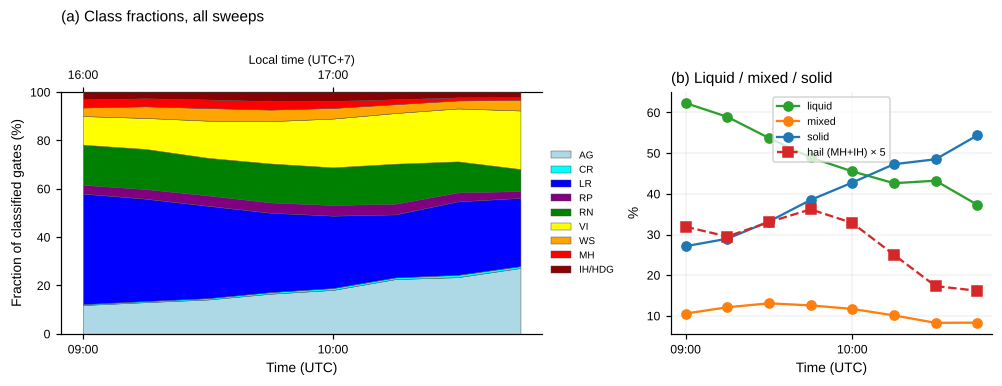

สัดส่วน (%) — liquid = LR+RN, mixed = RP+WS+MH, solid = AG+CR+VI+IH/HDG


,n_liquid,n_mixed,n_solid,hail_%
time,,,,
2024-05-03 09:00:00,62.3,10.6,27.1,6.38
2024-05-03 09:15:00,58.9,12.1,29.0,5.90
2024-05-03 09:30:00,53.7,13.1,33.2,6.61
2024-05-03 09:45:00,48.9,12.6,38.5,7.24
2024-05-03 10:00:00,45.5,11.7,42.8,6.57
2024-05-03 10:15:00,42.6,10.1,47.3,5.01
2024-05-03 10:30:00,43.2,8.3,48.5,3.46
2024-05-03 10:45:00,37.3,8.3,54.4,3.23


In [6]:
cls = pt.HID_NAMES[1:]
frac = hid_ts[cls].div(hid_ts[cls].sum(axis=1), axis=0) * 100
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].stackplot(frac.index, frac.T.values, colors=pt.HID_COLORS[1:], labels=cls, edgecolor="0.3", linewidth=0.3)
axs[0].set_ylabel("Fraction of classified gates (%)"); axs[0].set_ylim(0, 100)
axs[0].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=6.5, frameon=False)
mp.time_axis(axs[0], interval_h=1)
axs[0].set_title("(a) Class fractions, all sweeps", loc="left", pad=22)
grp = hid_ts[["n_liquid", "n_mixed", "n_solid"]].div(hid_ts[["n_liquid", "n_mixed", "n_solid"]].sum(axis=1), axis=0) * 100
for c_, col in zip(grp.columns, ("tab:green", "tab:orange", "tab:blue")):
    axs[1].plot(grp.index, grp[c_], "o-", color=col, label=c_[2:])
axs[1].plot(hid_ts.index, hid_ts["n_hail"] / hid_ts[cls].sum(axis=1) * 100 * 5, "s--", color="tab:red", label="hail (MH+IH) × 5")
axs[1].set_ylabel("%"); axs[1].legend(fontsize=7); axs[1].grid(lw=0.3, alpha=0.5)
mp.time_axis(axs[1], interval_h=1, local_top=False)
axs[1].set_title("(b) Liquid / mixed / solid", loc="left")
mp.save_figure(fig, "nb5_hid_fractions")
plt.show()
print("สัดส่วน (%) — liquid = LR+RN, mixed = RP+WS+MH, solid = AG+CR+VI+IH/HDG")
pd.concat([grp.round(1), (hid_ts["n_hail"] / hid_ts[cls].sum(axis=1) * 100).round(2).rename("hail_%")], axis=1)

- สัดส่วน **ของเหลว (ฝน)** ลดลงต่อเนื่องจาก ~60% (09:00) เหลือ ~40% (10:45) ขณะที่ **ของแข็ง (AG, VI)** เพิ่มจาก ~27% เป็น ~54%
- **ลูกเห็บ (MH + IH/HDG)** สูงสุดช่วง 09:30–10:00 UTC (16:30–17:00 น.) ตรงกับช่วงรายงานที่นากลาง แล้วลดลงชัดหลัง 10:15 UTC
- ภาพรวมคือพายุเข้าสู่ **ระยะสลาย (dissipating stage)** เหลือ anvil/stratiform ที่เป็นน้ำแข็ง
- นี่คือ **วงจรชีวิตของพายุฤดูร้อน** ที่มองเห็นผ่านชนิดหยาดน้ำฟ้า (เทียบกับ Byers & Braham, 1949)

## ✂️ 6. ภาคตัดขวาง (pseudo-RHI) ผ่านนากลาง

บันทึกรูปแล้ว: figures/nb5_cross_section_naklang.png, figures/nb5_cross_section_naklang.pdf


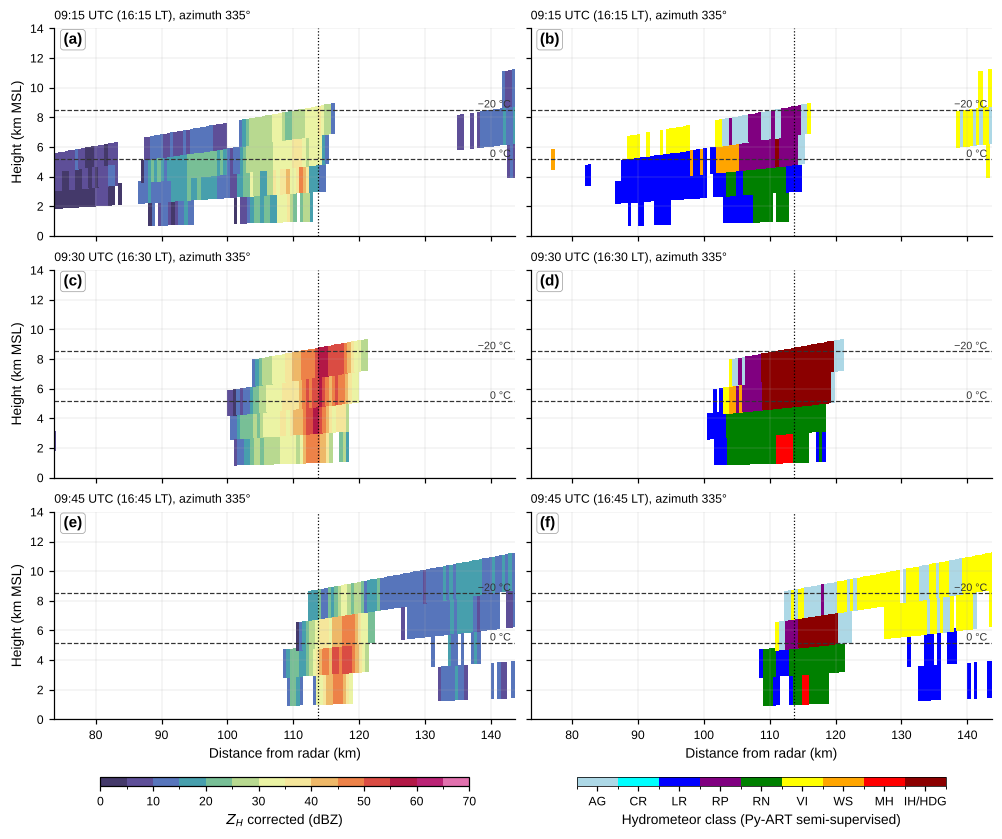

In [7]:
az_nk, rng_nk = pt.azimuth_to(meta, NK["lon"], NK["lat"])
times = list(vols)[1:4]                                  # 09:15, 09:30, 09:45
fig, axs = plt.subplots(len(times), 2, figsize=(9, 2.3 * len(times) + 0.6), sharex=True, sharey=True, layout="constrained")
for i, t in enumerate(times):
    xs = pt.cross_section(vols[t], az_nk)
    imz = pt.plot_rhi(axs[i, 0], xs, "DBZ_C", "Z", xlim=(rng_nk - 40, rng_nk + 30), isotherms=ISO)
    imh = pt.plot_rhi(axs[i, 1], xs, "HID", "HID", xlim=(rng_nk - 40, rng_nk + 30), isotherms=ISO)
    for ax in axs[i]:
        ax.axvline(rng_nk, color="k", lw=0.8, ls=":")
        ax.set_title(f"{mp.tlabel(t)}, azimuth {az_nk:.0f}°", loc="left", fontsize=8)
        if i < len(times) - 1:
            ax.set_xlabel("")
    if i > -1:
        axs[i, 1].set_ylabel("")
fig.colorbar(imz, ax=axs[:, 0], orientation="horizontal", shrink=0.8, pad=0.02, aspect=40, label="$Z_H$ corrected (dBZ)")
pt.hid_colorbar(fig, imh, axs[:, 1], shrink=0.8)
mp.panel_labels(axs.ravel())
mp.save_figure(fig, "nb5_cross_section_naklang")
plt.show()

**อ่านภาพ** (เส้นจุด = ตำแหน่งนากลาง, เส้นประ = ระดับ 0 °C และ −20 °C จาก sounding):
- ใต้ระดับ 0 °C: **RN และ MH** (ลูกเห็บกำลังละลายในชั้นอุ่น) ; เหนือระดับ 0 °C: **IH/HDG และ RP (graupel)** ในแกน Z สูง
- คอลัมน์ Z ≥ 45 dBZ ที่สูงเกินระดับ 0 °C หลายกิโลเมตร = updraft แรงพอจะพาน้ำขึ้นไปเยือกแข็งและโตเป็นลูกเห็บ (สอดคล้องเกณฑ์ Waldvogel ใน repo pysteps NB2)
- ⚠️ มีเพียง **4 มุมยก** → ภาพแนวตั้งหยาบ ช่องว่างระหว่างมุมยกคือส่วนที่เรดาร์ไม่ได้วัด

## 🎛️ 7. ผลไวต่อ ZDR และระดับเยือกแข็ง

In [8]:
r = vols[list(vols)[2]]                                  # 09:30
base = np.ma.filled(r.fields["HID"]["data"], 0).copy()
tests = {}
zc = pt.field_data(r, "ZDR_C")
for dz in (-0.3, +0.3):
    pt.add_field(r, "ZDR_T", zc + dz, "dB")
    pt.classify_hid(r, zdr="ZDR_T", name="HID_T")
    tests[f"ZDR {dz:+.1f} dB"] = np.ma.filled(r.fields["HID_T"]["data"], 0)
T = pt.field_data(r, "temperature")
for dT, lab in ((+3.25, "0 °C level +500 m"), (-3.25, "0 °C level −500 m")):
    pt.add_field(r, "T_T", T + dT, "degC", mask_invalid=False)
    pt.classify_hid(r, temp="T_T", name="HID_T")
    tests[lab] = np.ma.filled(r.fields["HID_T"]["data"], 0)
valid = base > 0
sens = pd.DataFrame({k: {"changed_%": 100 * np.mean(v[valid] != base[valid]),
                         "hail_gates": int(np.isin(v, pt.HID_GROUPS["hail"]).sum()),
                         "graupel_gates": int(np.isin(v, pt.HID_GROUPS["graupel"]).sum())} for k, v in tests.items()}).T
sens.loc["baseline"] = [0.0, int(np.isin(base, pt.HID_GROUPS["hail"]).sum()), int(np.isin(base, pt.HID_GROUPS["graupel"]).sum())]
sens.round(1)

,changed_%,hail_gates,graupel_gates
ZDR -0.3 dB,6.6,2704.0,1742.0
ZDR +0.3 dB,6.8,2901.0,1872.0
0 °C level +500 m,11.4,2685.0,1667.0
0 °C level −500 m,11.4,3150.0,2326.0
baseline,0.0,2782.0,1807.0


- การเปลี่ยน ZDR เพียง ±0.3 dB (ขนาดเท่า bias ที่แก้ใน NB4) ทำให้ **คลาสเปลี่ยนหลายเปอร์เซ็นต์ของ gate** → ต้องแก้ ZDR bias เสมอ
- sounding 00Z อยู่ก่อนพายุหลายชั่วโมง ตอนบ่ายระดับ 0 °C อาจสูงขึ้น → ผลต่อคลาสใกล้ชั้นละลาย (WS, MH vs IH) ชัดเจน
- **ข้อเสนอสำหรับงานวิจัย:** รายงานผล HID พร้อมช่วงความไม่แน่นอน (ensemble ของการตั้งค่าที่เป็นไปได้)

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 5.1: สร้างตัวจำแนก fuzzy 3 คลาสด้วยตัวเอง
สร้าง membership แบบสี่เหลี่ยมคางหมู `trap(x, a, b, c, d)` สำหรับ 3 คลาส: **ฝน (rain)**, **ลูกเห็บ/graupel (hail)**, **น้ำแข็งเบา (ice)**
จาก 3 ตัวแปร Z, ZDR และ T (น้ำหนักเท่ากัน) แล้วจำแนก volume 09:30 และเทียบกับกลุ่มของ Py-ART
(rain = LR+RN, hail = RP+MH+IH/HDG, ice = AG+CR+VI+WS)

| คลาส | Z (dBZ) | ZDR (dB) | T (°C) |
|---|---|---|---|
| rain | 10–15 … 50–55 | 0–0.3 … 3–5 | 0–2 … 40–45 |
| hail | 35–45 … 70–75 | −1 … 0.5–1.5 (ลดลงถึง 2.5) | −40 … 5–15 |
| ice | −10 … 25–35 | −1 … 0.5–1.5 (ถึง 2) | −60 … −2–0 |

**คำถาม:** ตัวจำแนกของคุณตรงกับ Py-ART กี่ %? คลาสใดสับสนกันมากที่สุด และเพราะอะไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `def trap(x, a, b, c, d): return np.clip(np.minimum((x - a) / (b - a), (d - x) / (d - c)), 0, 1)`
- `S = np.stack([S_rain, S_hail, S_ice]); cls = np.argmax(S, axis=0)`
- ตาราง confusion: `pd.crosstab(mine, pyart_group)`

</details>

In [9]:
# ✍️ แบบฝึกหัด 5.1 — เขียนโค้ดของคุณที่นี่

In [10]:
#@title ✅ เฉลยแบบฝึกหัด 5.1
def trap(x, a, b, c, d):
    """membership รูปสี่เหลี่ยมคางหมู: 0 นอก [a, d], 1 ใน [b, c]"""
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.clip(np.minimum((x - a) / (b - a), (d - x) / (d - c)), 0, 1)

r = vols[list(vols)[2]]
Z, ZDR, T = pt.field_data(r, "DBZ_C"), pt.field_data(r, "ZDR_C"), pt.field_data(r, "temperature")
S = np.stack([
    (trap(Z, 10, 15, 50, 55) + trap(ZDR, 0, 0.3, 3, 5) + trap(T, 0, 2, 40, 45)) / 3,          # rain
    (trap(Z, 35, 45, 70, 75) + trap(ZDR, -1.5, -1, 0.5, 2.5) + trap(T, -45, -40, 5, 15)) / 3,  # hail
    (trap(Z, -15, -10, 25, 35) + trap(ZDR, -1.5, -1, 1.5, 2) + trap(T, -65, -60, -2, 0)) / 3,  # ice
])
h = np.ma.filled(r.fields["HID"]["data"], 0)
ok = (h > 0) & np.isfinite(S).all(axis=0)
mine = np.array(["rain", "hail", "ice"])[np.argmax(np.nan_to_num(S), axis=0)]
group = np.full(h.shape, "", dtype=object)
for name, ids in (("rain", [3, 5]), ("hail", [4, 8, 9]), ("ice", [1, 2, 6, 7])):
    group[np.isin(h, ids)] = name
ct = pd.crosstab(pd.Series(mine[ok], name="my fuzzy"), pd.Series(group[ok], name="Py-ART group"))
print(ct)
agree = np.mean(mine[ok] == group[ok]) * 100
print(f"\n→ ตรงกัน {agree:.1f}% ของ gate")
off = ct.stack()
off = off[[i != j for i, j in off.index]].sort_values(ascending=False)
print("  คู่ที่สับสนมากที่สุด (ของเรา → Py-ART):", ", ".join(f"{i}→{j} ({n:,})" for (i, j), n in off.head(3).items()))
print("  - Py-ART 'hail' ที่เราเรียก rain: ส่วนใหญ่คือ MH ใต้ 0 °C (Z สูง + ZDR สูง เหมือนฝนเม็ดใหญ่ ต้องใช้ KDP/ρHV ช่วยแยก)"
      "\n  - ice ↔ rain: ฝนเบาใกล้ระดับ 0 °C/ระยะไกล ที่ Z ต่ำและ ZDR ต่ำ — T จาก sounding เป็นตัวตัดสินหลัก จึงไวต่อระดับเยือกแข็ง"
      "\n  - ice ↔ hail: graupel (RP) ที่ Z 25–35 dBZ อยู่ระหว่างสองคลาสของเรา")

Py-ART group  hail    ice   rain
my fuzzy                        
hail          1382    832    685
ice           1585  13014   3916
rain          1622   1036  18014

→ ตรงกัน 77.0% ของ gate
  คู่ที่สับสนมากที่สุด (ของเรา → Py-ART): ice→rain (3,916), rain→hail (1,622), ice→hail (1,585)
  - Py-ART 'hail' ที่เราเรียก rain: ส่วนใหญ่คือ MH ใต้ 0 °C (Z สูง + ZDR สูง เหมือนฝนเม็ดใหญ่ ต้องใช้ KDP/ρHV ช่วยแยก)
  - ice ↔ rain: ฝนเบาใกล้ระดับ 0 °C/ระยะไกล ที่ Z ต่ำและ ZDR ต่ำ — T จาก sounding เป็นตัวตัดสินหลัก จึงไวต่อระดับเยือกแข็ง
  - ice ↔ hail: graupel (RP) ที่ Z 25–35 dBZ อยู่ระหว่างสองคลาสของเรา


### 🧪 แบบฝึกหัด 5.2: สัญญาณลูกเห็บรอบจุดรายงานเปลี่ยนตามเวลาอย่างไร?
สำหรับ **ภูกระดึง (06:30–08:30 UTC)** และ **นากลาง (08:45–10:45 UTC)** นับจำนวน gate ที่เป็น MH หรือ IH/HDG **และ** $Z_H$ ≥ 40 dBZ
ภายในรัศมี 15 km (ทุกมุมยก) แล้วพลอตเทียบกับเวลารายงาน (14:00 และ ~16:30 น.)

**คำถาม:** สัญญาณลูกเห็บนำหน้าหรือตามหลังรายงาน? สัญญาณที่สองจุดต่างกันอย่างไร และเวลาในรายงานข่าวเชื่อถือได้แค่ไหน?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ใช้ `prepare(pt.read_volume(f))` แล้ว `pt.classify_hid(r)`
- mask: `pt.site_gates(r, meta, lon, lat, 15)` & `np.isin(h, [8, 9])` & `(pt.field_data(r, "DBZ_C") >= 40)`
- เวลารายงาน: `kt.report_time_utc(PK, date0)`

</details>

In [11]:
# ✍️ แบบฝึกหัด 5.2 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb5_ex52_hail_sites.png, figures/nb5_ex52_hail_sites.pdf


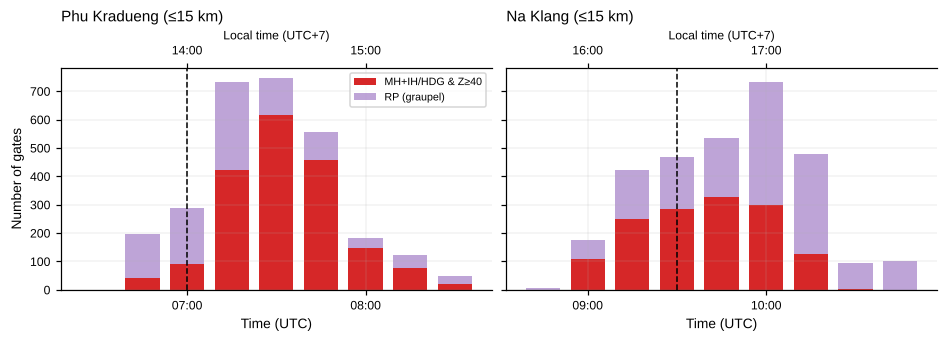

site                Na Klang Phu Kradueng
time                                     
2024-05-03 06:30:00        —          0.0
2024-05-03 06:45:00        —         41.0
2024-05-03 07:00:00        —         92.0
2024-05-03 07:15:00        —        423.0
2024-05-03 07:30:00        —        617.0
2024-05-03 07:45:00        —        458.0
2024-05-03 08:00:00        —        147.0
2024-05-03 08:15:00        —         78.0
2024-05-03 08:30:00        —         22.0
2024-05-03 08:45:00      0.0            —
2024-05-03 09:00:00    109.0            —
2024-05-03 09:15:00    249.0            —
2024-05-03 09:30:00    286.0            —
2024-05-03 09:45:00    326.0            —
2024-05-03 10:00:00    300.0            —
2024-05-03 10:15:00    127.0            —
2024-05-03 10:30:00      2.0            —
2024-05-03 10:45:00      1.0            —
→ Phu Kradueng: สัญญาณลูกเห็บสูงสุด 617 gate เวลา 07:30 UTC (ต่างจากรายงาน +30 นาที)
→ Na Klang: สัญญาณลูกเห็บสูงสุด 326 gate เวลา 09:45 UTC (ต่างจากรายงาน +15 

In [12]:
#@title ✅ เฉลยแบบฝึกหัด 5.2
date0 = pt.volume_time(radar).replace(hour=0, minute=0)
rows = []
for name, s, t0_, t1_ in (("Phu Kradueng", PK, "06:30", "08:30"), ("Na Klang", NK, "08:45", "10:45")):
    for f in pt.polar_files(DATA, t0_, t1_):
        r = prepare(pt.read_volume(f)); pt.classify_hid(r)
        h = np.ma.filled(r.fields["HID"]["data"], 0)
        m = pt.site_gates(r, meta, s["lon"], s["lat"], 15)
        z = pt.field_data(r, "DBZ_C")
        rows.append({"site": name, "time": pt.volume_time(r), "hail_gates": int((m & np.isin(h, [8, 9]) & (z >= 40)).sum()),
                     "graupel_gates": int((m & (h == 4)).sum()), "Zmax": np.nanmax(np.where(m, z, np.nan))})
hs = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3), layout="constrained", sharey=True)
for ax, (name, s) in zip(axs, (("Phu Kradueng", PK), ("Na Klang", NK))):
    d = hs[hs.site == name]
    ax.bar(d["time"], d["hail_gates"], width=0.008, color="tab:red", label="MH+IH/HDG & Z≥40")
    ax.bar(d["time"], d["graupel_gates"], width=0.008, bottom=d["hail_gates"], color="tab:purple", alpha=0.6, label="RP (graupel)")
    ax.axvline(kt.report_time_utc(s, date0), color="k", ls="--", lw=1)
    ax.set_title(f"{name} (≤15 km)", loc="left"); ax.grid(lw=0.3, alpha=0.5)
    mp.time_axis(ax, interval_h=1)
axs[0].set_ylabel("Number of gates"); axs[0].legend(fontsize=7)
mp.save_figure(fig, "nb5_ex52_hail_sites")
plt.show()
print(hs.pivot(index="time", columns="site", values="hail_gates").fillna("—"))
for name, s in (("Phu Kradueng", PK), ("Na Klang", NK)):
    d = hs[hs.site == name]
    tpk = d.loc[d["hail_gates"].idxmax(), "time"]
    lag = (tpk - kt.report_time_utc(s, date0)).total_seconds() / 60
    print(f"→ {name}: สัญญาณลูกเห็บสูงสุด {d['hail_gates'].max()} gate เวลา {tpk:%H:%M} UTC (ต่างจากรายงาน {lag:+.0f} นาที)")
print("  สัญญาณสูงสุดมาหลังเวลารายงาน 15–30 นาที: เวลาในข่าวเป็นค่าประมาณ (ปัดเป็น 14:00/16:30 น.) และ gate ที่นับรวม IH/HDG ที่อยู่สูง"
      "\n  ซึ่งยังไม่ตกถึงพื้น — ช่วงที่ 'เริ่ม' มีสัญญาณ (ภูกระดึง 06:45–07:00, นากลาง 09:00) ตรงกับรายงานดีกว่าช่วงสูงสุด"
      "\n  ภูกระดึงมีสัญญาณมากกว่าแต่สั้นกว่า (เซลล์บนภูเขาที่โตเร็ว) ขณะที่นากลางคงอยู่นานราว 1 ชั่วโมง (09:00–10:00 UTC)")

### 🧪 แบบฝึกหัด 5.3: ZDR ±0.3 dB เปลี่ยนคลาสไหนเป็นคลาสไหน?
จากผลใน section 7 สร้าง **ตาราง confusion** ระหว่าง `base` กับผลที่ ZDR −0.3 dB และ +0.3 dB (ใช้ชื่อคลาส)
แล้วหาคู่คลาสที่เปลี่ยนกันมากที่สุด 5 อันดับ

**คำถาม:** การเปลี่ยนแปลงสมเหตุสมผลทางฟิสิกส์หรือไม่ (เช่น ZDR ลดลง → คลาสไหนเพิ่ม)?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ชื่อคลาส: `np.array(pt.HID_NAMES)[base]`
- `pd.crosstab(a, b)` แล้ว `.stack()` และ `.sort_values(ascending=False)` (ตัดแนวทแยงออก)

</details>

In [13]:
# ✍️ แบบฝึกหัด 5.3 — เขียนโค้ดของคุณที่นี่

In [14]:
#@title ✅ เฉลยแบบฝึกหัด 5.3
names = np.array(pt.HID_NAMES)
for key in ("ZDR -0.3 dB", "ZDR +0.3 dB"):
    v = tests[key]
    a, b = names[base[valid].astype(int)], names[v[valid].astype(int)]
    ct = pd.crosstab(pd.Series(a, name="baseline"), pd.Series(b, name=key))
    st_ = ct.stack()
    st_ = st_[[i != j for i, j in st_.index]].sort_values(ascending=False)
    print(f"\n{key}: คู่ที่เปลี่ยนมากที่สุด (baseline → ใหม่, จำนวน gate)")
    print(st_.head(5).to_string())
print("\n→ ZDR ลดลง: คลาสที่ ZDR ต่ำ/ติดลบ (VI, IH/HDG, AG) เพิ่ม และ LR→VI/AG ในบริเวณใกล้ 0 °C"
      "\n  ZDR เพิ่มขึ้น: ฝนเบา→ฝน (LR→RN) และ AG→WS/CR — สอดคล้องกับ centroid ใน section 1 (ZDR ของ VI ติดลบ, RN สูงกว่า LR)")


ZDR -0.3 dB: คู่ที่เปลี่ยนมากที่สุด (baseline → ใหม่, จำนวน gate)
baseline  ZDR -0.3 dB
AG        VI             1589
RN        LR              407
MH        RN              213
CR        VI              140
WS        LR              108

ZDR +0.3 dB: คู่ที่เปลี่ยนมากที่สุด (baseline → ใหม่, จำนวน gate)
baseline  ZDR +0.3 dB
VI        AG             1561
LR        RN              412
RN        MH              232
VI        CR              231
IH/HDG    RP              100

→ ZDR ลดลง: คลาสที่ ZDR ต่ำ/ติดลบ (VI, IH/HDG, AG) เพิ่ม และ LR→VI/AG ในบริเวณใกล้ 0 °C
  ZDR เพิ่มขึ้น: ฝนเบา→ฝน (LR→RN) และ AG→WS/CR — สอดคล้องกับ centroid ใน section 1 (ZDR ของ VI ติดลบ, RN สูงกว่า LR)


---
## 📝 สรุป
- HID ของ Py-ART (Besic et al., 2016) จำแนกจาก **ระยะทางถึง centroid** ใน 5 มิติ และให้ **entropy** บอกความไม่แน่นอน
- พายุที่นากลาง 09:00–09:45 UTC มี **MH ใต้ระดับ 0 °C และ IH/HDG/RP เหนือระดับ 0 °C** สอดคล้องกับรายงานลูกเห็บ ~16:30 น.
- หลัง 10:00 UTC สัดส่วนน้ำแข็ง (AG/VI) เพิ่ม ฝนและลูกเห็บลด = **ระยะสลายของพายุ**
- ผลไวต่อ **ZDR bias และระดับเยือกแข็ง** → ต้องเตรียมข้อมูล (NB4) ให้ดี และรายงานความไม่แน่นอน

### ❓ คำถามชวนคิด
1. ทำไม VI (ผลึกน้ำแข็งเรียงตัวในแนวดิ่ง) จึงเพิ่มขึ้นในช่วงที่พายุแก่ตัว? เกี่ยวข้องกับฟ้าผ่าอย่างไร
2. ถ้าจะใช้ HID ทำ **ระบบเตือนลูกเห็บ** สำหรับเกษตรกรในอีสาน ควรใช้คลาสใด เกณฑ์อะไร และต้องระวังอะไร?
3. centroid ของ Besic et al. ได้จากข้อมูลในยุโรป (สวิตเซอร์แลนด์) — ใช้กับพายุเขตร้อนได้ดีแค่ไหน? จะปรับให้เหมาะกับประเทศไทยได้อย่างไร

**🚀 ต่อยอด (ป.โท):** ใช้ไฟล์ 92 volume คำนวณ HID ทั้งวัน (ดู NB6) แล้วเก็บสถิติ centroid จริงของ KKN ด้วย k-means
เปรียบเทียบกับ centroid ของ Py-ART — เป็นจุดเริ่มต้นของ **HID ที่ปรับสำหรับเรดาร์ C-band ของ TMD**

### 📚 เอกสารอ้างอิง
- Besic, N., Figueras i Ventura, J., Grazioli, J., Gabella, M., Germann, U., & Berne, A. (2016). Hydrometeor classification through statistical clustering of polarimetric radar measurements: a semi-supervised approach. *Atmos. Meas. Tech.*, 9, 4425–4445.
- Straka, J. M., Zrnić, D. S., & Ryzhkov, A. V. (2000). Bulk hydrometeor classification and quantification using polarimetric radar data: Synthesis of relations. *J. Appl. Meteor.*, 39, 1341–1372.
- Liu, H., & Chandrasekar, V. (2000). Classification of hydrometeors based on polarimetric radar measurements: Development of fuzzy logic and neuro-fuzzy systems, and in situ verification. *J. Atmos. Oceanic Technol.*, 17, 140–164.
- Dolan, B., & Rutledge, S. A. (2009). A theory-based hydrometeor identification algorithm for X-band polarimetric radars. *J. Atmos. Oceanic Technol.*, 26, 2071–2088.
- Byers, H. R., & Braham, R. R. (1949). *The Thunderstorm*. U.S. Government Printing Office.